# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Kaitlin Luu, Natalie Schweickert, James Torgerson"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.
- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.
- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

To perform exploratory and descriptive analyses, we will first gather information about the data's structure with .describe and .info. We will then check for missing values using df.isna().sum() and examine the eight input features. Next, we will plot the distribution of every variable using histograms or KDE plots to get a sense of the shape, skew, and any outliers. We can also create a correlation matrix to look at relationships between the input variables, which will help us determine if there is any multicollinearity.  

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

For preprocessing, we would first check for any missing values or duplicates in the dataset. We would then standardize the input features using StandardScaler (mean = 0, standard deviation = 1) in order to account for differences in feature scales. Then, by fitting this scaler on the training data within each cross-validation fold, we can use this to transform the validation data. Lastly, we would convert the data to PyTorch tensors. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

The outcome variable (`Concrete compressive strength(MPa, megapascals)`) is a continuous quantitative variable with a minimum of ~2.331 and a maximum of ~82.599. So, to predict this variable, we will be doing regression (as opposed to classification) because we are not predicting distinct classes and are instead predicting a value along a numeric scale. Since we are going linear regression, our cost function will be MSE and our output layer activation function will be linear/default (as in, leaving our prediction as a linear combination) -- with hidden layers using RELU.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

[text here]

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [23]:
import pandas as pd
df = pd.read_excel('Concrete_Data.xls')
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [24]:
df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [26]:
df.isna().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

In [27]:
print(df.columns)

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')


<Axes: >

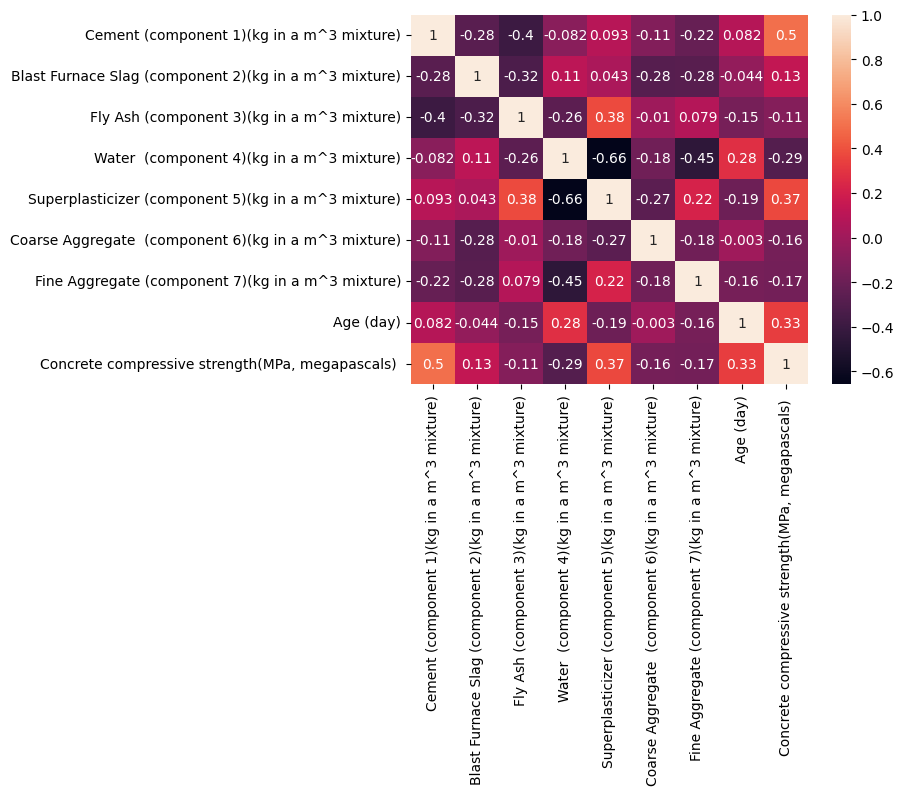

In [28]:
# print a correlation matrix only using the numeric data types in df
import seaborn as sns
numeric_features = df.select_dtypes(include=["int64", "float64"])
corr_matrix = numeric_features.corr()
sns.heatmap(corr_matrix, annot=True)

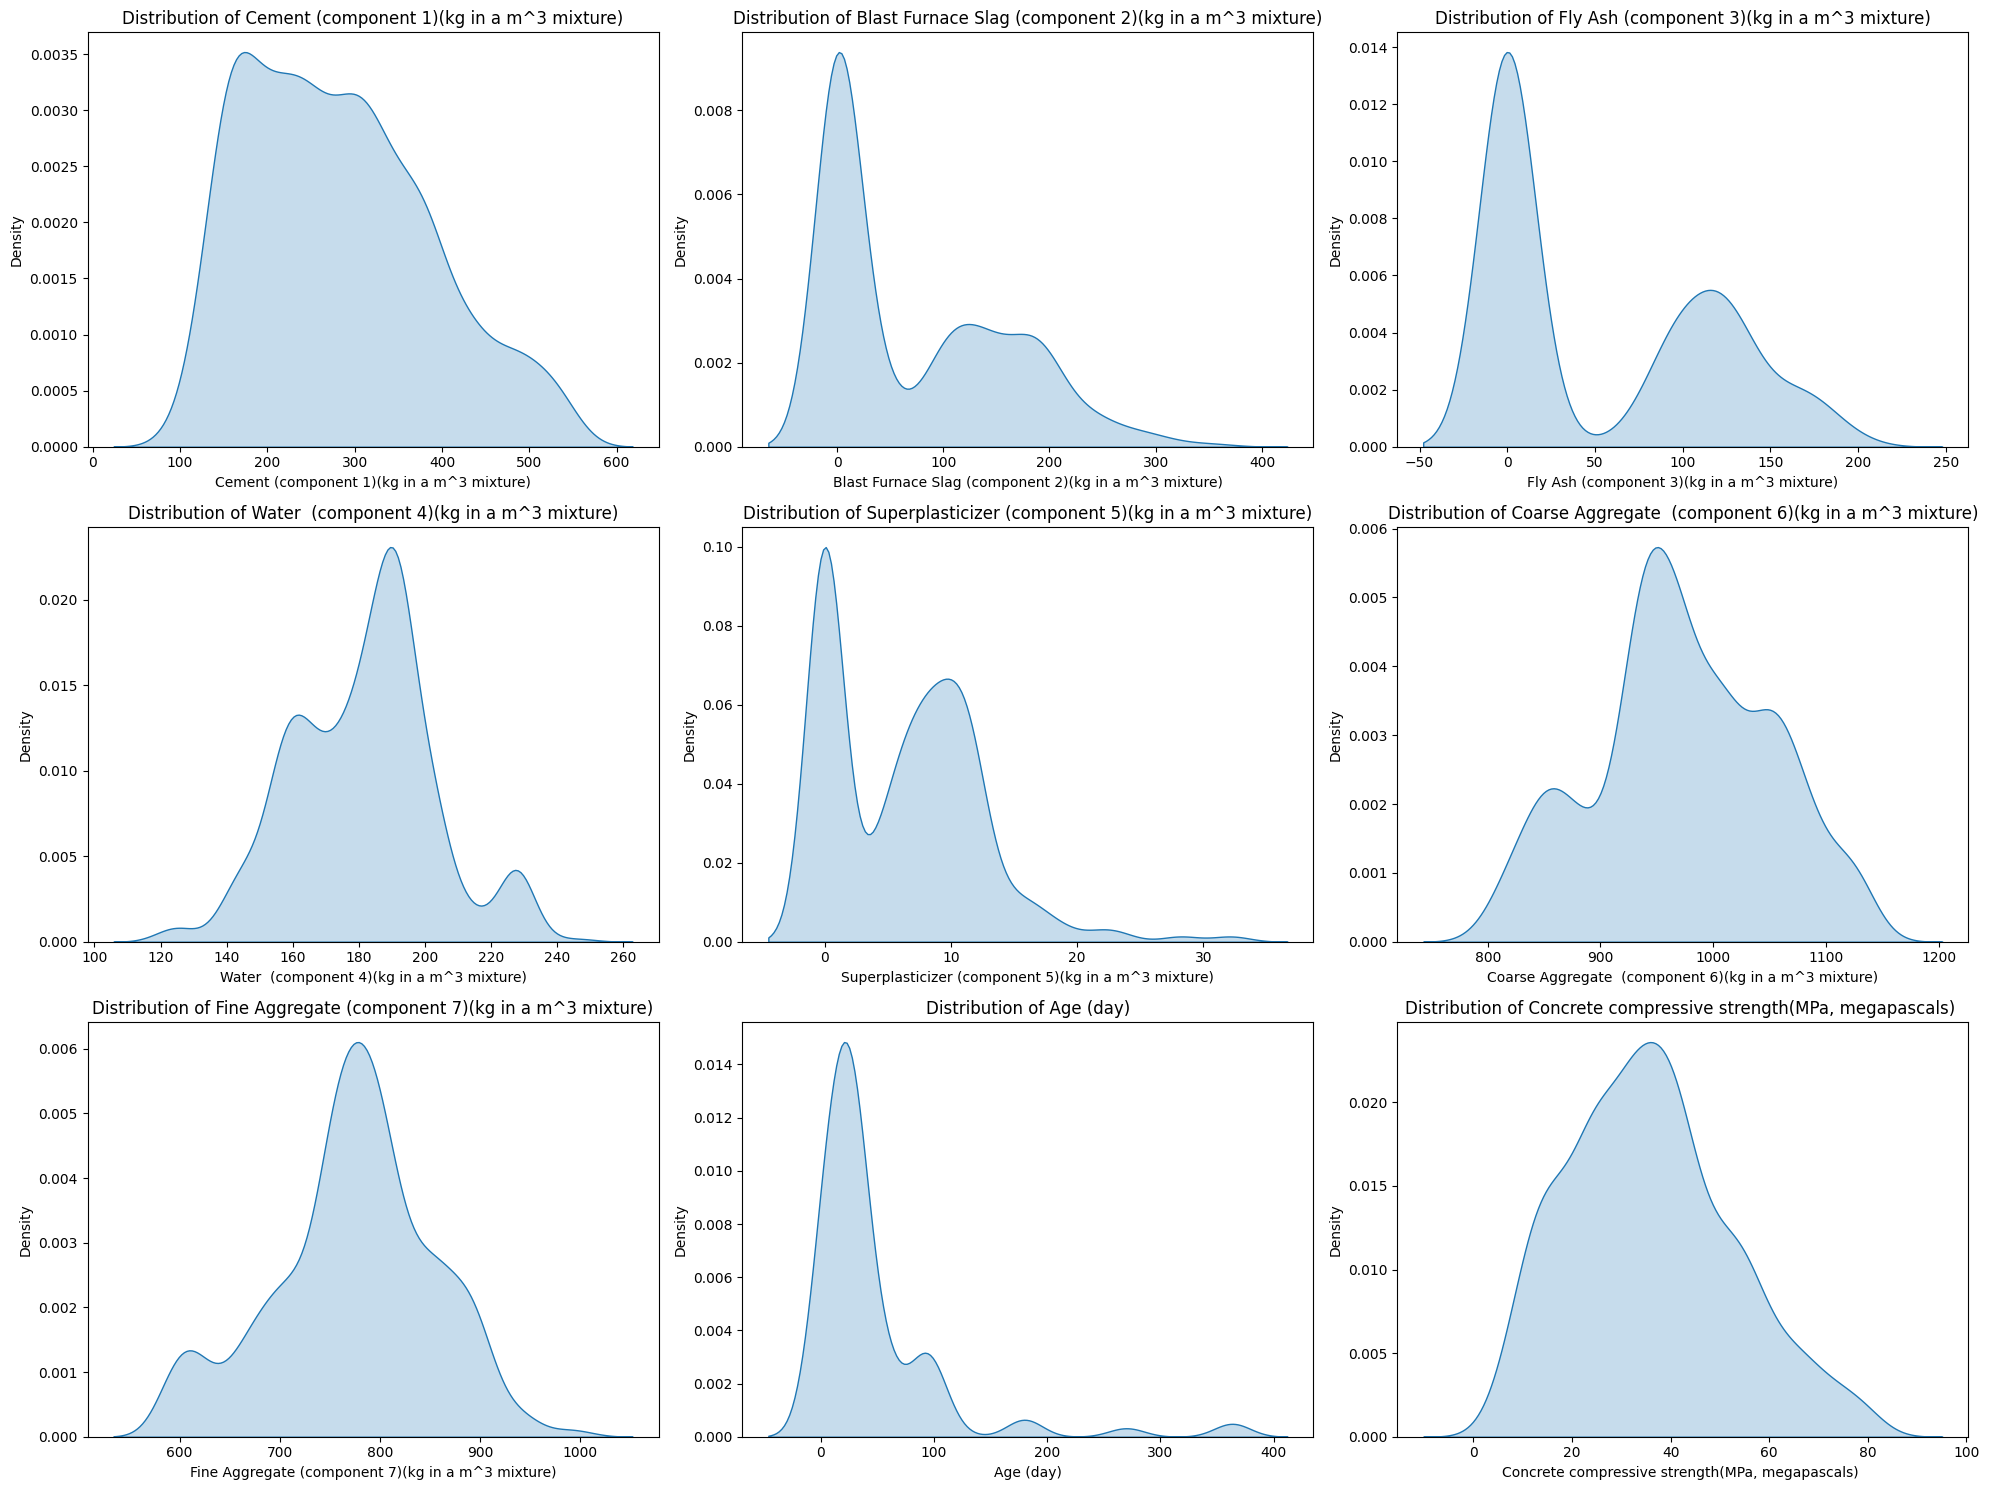

In [29]:
import matplotlib.pyplot as plt
num_cols = numeric_features.shape[1]

plt.figure(figsize=(20, 15))

for i in range(num_cols):
    col = numeric_features.columns[i]
    plt.subplot(3, 3, i + 1)
    sns.kdeplot(numeric_features[col], fill=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Density")

plt.tight_layout()
plt.show()

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [ ]:
# defining model
import torch
import torch.nn as nn
import torch.optim as optim

class NeuralNetwork(nn.Module): #inherit from nn.Module
    def __init__(self):
        super().__init__()  

        n_features = 8    
        hidden_size = 16

        l1 = nn.Linear(n_features, hidden_size)
        a1 = nn.ReLU()
        l2 = nn.Linear(hidden_size, 1)
        a2 = nn.Identity() # we can also leave a2 out b/c we will leave it as linear combination for regression - but wanted to code it as identity for clarity on structure of neural network :)
        l = [l1, a1, l2, a2]
        self.module_list = nn.ModuleList(l)

    def forward(self, X):
        for layer in self.module_list:
            X = layer(X)
        return X


# cost
cost_function = nn.MSELoss() # b/c we are doing regression

In [40]:
# data preprocessing
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Concrete compressive strength(MPa, megapascals) '])
y = df['Concrete compressive strength(MPa, megapascals) ']

In [ ]:
# instantiation + evaluation w/ KFold

from sklearn.model_selection import KFold
from sklearn.metrics import r2_score #

k = 5
batch_size = 16
n_epochs = 100
kf = KFold(n_splits=k, shuffle=True, random_state=42)

## set up lists for evaluation
fold_mse = []
fold_rmse = []
fold_r2 = []

for fold, (ii, jj) in enumerate(kf.split(X), start=1):
    # split
    X_train, X_report = X.iloc[ii], X.iloc[jj]
    y_train, y_report = y.iloc[ii], y.iloc[jj]

    # scale
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_report = scaler.transform(X_report)

    # make into tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
    X_report = torch.tensor(X_report, dtype=torch.float32)
    y_report = torch.tensor(y_report.values, dtype=torch.float32).reshape(-1, 1)

    #use DataLoader for batch processing
    train_dataset = TensorDataset(X_train, y_train) 
    train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle=True)

    report_dataset = TensorDataset(X_report, y_report)
    report_loader = DataLoader(report_dataset, batch_size=batch_size, shuffle=False)

    # instantiate model + optimizer for each fold
    model = NeuralNetwork()
    cost_function = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # train
    train_costs=[] # reset at start of each fold

    for epoch in range(n_epochs):
        model.train() 

        running_cost = 0
        
        for x_batch, y_batch in train_loader:
            optimizer.zero_grad()
            y_probs = model(x_batch)
            cost = cost_function(y_probs, y_batch)
            cost.backward()
            optimizer.step()
            running_cost += cost.item()

        train_costs.append(running_cost / len(train_loader))

    # evaluation
    model.eval() 
    report_cost = 0.0
    total = 0
    preds=[]
    with torch.no_grad():  # No gradient tracking
        for x_batch, y_batch in report_loader:
            out = model(x_batch)
            cost = cost_function(out, y_batch)
            report_cost += cost.item() * x_batch.size(0)  
            total += y_batch.size(0)
            preds.append(out)

    mse = report_cost / len(jj) # we evalute using mse b/c that is te cost function for linear regression
    r2 = r2 = r2_score(y_report.numpy(), torch.cat(preds).numpy()) # we evaluate w/ r2 because it tells us how much variance in Y is explained by X
    fold_mse.append(mse)
    fold_rmse.append(np.sqrt(mse)) # root MSE to return to original units -- useful if we need to interpret later :)
    fold_r2.append(r2)
    print(f"Fold {fold}: MSE={mse:.2f}, RMSE={np.sqrt(mse):.2f}, R²={r2:.3f}")

    # per-fold sanity check :)
    avg_report_loss = report_cost / total
    print(f"Reporting Loss: {avg_report_loss:.4f}", "\n")



Fold 1: MSE=85.59, RMSE=9.25, R²=0.668
Reporting Loss: 85.5863 

Fold 2: MSE=80.25, RMSE=8.96, R²=0.760
Reporting Loss: 80.2521 

Fold 3: MSE=101.31, RMSE=10.07, R²=0.642
Reporting Loss: 101.3086 

Fold 4: MSE=76.36, RMSE=8.74, R²=0.729
Reporting Loss: 76.3620 

Fold 5: MSE=78.38, RMSE=8.85, R²=0.668
Reporting Loss: 78.3759 



In [48]:
print(f"\nAverage over {k} folds:")
print(f"MSE:  {np.mean(fold_mse):.2f}")
print(f"RMSE: {np.mean(fold_rmse):.2f}")
print(f"R²:   {np.mean(fold_r2):.3f}")


Average over 5 folds:
MSE:  84.38
RMSE: 9.17
R²:   0.693


## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [5]:
# USE AS MANY CELLS AS NEEDED

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [6]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE